# Learning Pandas with CWRU data set
- Pierian Data courses on Bilibili
- Pandas is created for analyzing finacial data, especially with time series data
- it is based on numpy library, but introduced new data type including series/data frame
- now use DWRU data set to exercise with Pandas module

## CWRU data set
- Data was collected for normal bearings, single-point drive end and fan end defects. 
- Data was collected at 12,000 samples/second and at 48,000 samples/second for drive end bearing experiments. 
- All fan end bearing data was collected at 12,000 samples/second.  

- Data files are in Matlab format.  Each file contains fan and drive end vibration data as well as motor rotational speed.  For all files, the following item in the variable name indicates:
    * DE - drive end accelerometer data
    * FE - fan end accelerometer data
    * BA - base accelerometer data
    * time - time series data
    * RPM - rpm during testing

<!---
<img src=".\CWRU-dataset-main\Normal.png" alt="Sample" width="70%">
<img src=".\CWRU-dataset-main\12k_Drive_End_Bearing_Fault_Data.png" alt="Sample" width="70%">
<img src=".\CWRU-dataset-main\12k_Fan_End_Bearing_Fault_Data.png" alt="Sample" width="70%">
<img src=".\CWRU-dataset-main\48k_Drive_End_Bearing_Fault_Data.png" alt="Sample" width="70%">
-->


In [1]:
# import libraries
import numpy as np
import pandas as pd
from scipy.io import loadmat
#%matplotlib widget
import matplotlib.pyplot as plt

In [91]:
# load cwru data set matfile
file_path = "D:\\codebase\\Machine-Learning-Notebooks-master\\4_exercise\\cwru\\CWRU-dataset-main"

mat_file_dict = {
    "normal" : {"filename": "\\Normal\\97_Normal_0.mat",
                "rpm":1796,
                "datablock":['X097_DE_time','X097_FE_time'] },
    
    "fault_IR_007" : {"filename":  "\\12k_Fan_End_Bearing_Fault_Data\\IR\\007\\278_0.mat", 
                      "rpm":1796,
                      "datablock":['X278_DE_time','X278_FE_time'] },
    
    "fault_OR_007" : {"filename":  "\\12k_Fan_End_Bearing_Fault_Data\\OR\\007\\@3\\298_0.mat", 
                  "datablock":['X298_DE_time','X298_FE_time'] },
    
    "fault_B_007" : {"filename":  "\\12k_Fan_End_Bearing_Fault_Data\\B\\007\\282_0.mat", 
              "datablock":['X282_DE_time','X282_FE_time'] },
}

def load_mat_data(file, num_samples, data_block):
    mat_data = loadmat(file)
    data1 = data_block[0]
    data2 = data_block[1]
    print(mat_data.items()) # View dict items
    #print(mat_data[data1].shape)
    #print(mat_data[data2].shape)

    # cut down data set, memory is not enough ...
    mat_data[data1] = mat_data[data1][:num_samples]
    mat_data[data2] = mat_data[data2][:num_samples]
    #print("in total samples: %s" %num_samples)
    
    return mat_data

def test_load_mat_data():
    num_samples = 2000
    dataset = "fault_OR_007"
    mat_data = load_mat_data(file_path+mat_file_dict[dataset]["filename"], num_samples, mat_file_dict[dataset]["datablock"])
    print(mat_data)
    
test_load_mat_data()

dict_items([('__header__', b'MATLAB 5.0 MAT-file, Platform: PCWIN, Created on: Thu Jun 29 14:30:53 2000'), ('__version__', '1.0'), ('__globals__', []), ('X298_DE_time', array([[ 0.00584623],
       [ 0.10458251],
       [-0.02590204],
       ...,
       [-0.01924383],
       [ 0.00901293],
       [ 0.03203246]])), ('X298_FE_time', array([[-0.13427245],
       [ 0.01190733],
       [ 0.06445403],
       ...,
       [-0.07595497],
       [ 0.09347053],
       [ 0.10196416]])), ('X298_BA_time', array([[-0.05166481],
       [ 0.09077555],
       [-0.08920629],
       ...,
       [-0.12413234],
       [ 0.09013175],
       [ 0.17129056]])), ('X298RPM', array([[1797]], dtype=uint16))])
{'__header__': b'MATLAB 5.0 MAT-file, Platform: PCWIN, Created on: Thu Jun 29 14:30:53 2000', '__version__': '1.0', '__globals__': [], 'X298_DE_time': array([[ 0.00584623],
       [ 0.10458251],
       [-0.02590204],
       ...,
       [-0.02866275],
       [ 0.04668862],
       [ 0.03901545]]), 'X298_FE_time'

In [66]:
# create DF for fault data

sample_freq = 12000.0

def create_df_from_mat_data(dataset_name, num_samples):
    mat_data = load_mat_data(file_path+mat_file_dict[dataset_name]["filename"], num_samples, 
                             mat_file_dict[dataset_name]["datablock"])
    acc_data = []
    data1 = mat_file_dict[dataset_name]["datablock"][0]
    data2 = mat_file_dict[dataset_name]["datablock"][1]


    acc_data = np.concatenate((mat_data[data1].astype(np.float32), 
                               mat_data[data2].astype(np.float32)), 
                              axis=1)
    #print(acc_data.shape)
    df = pd.DataFrame(data=acc_data,columns=[data1, data2])
    
    # add timestamp
    df.index = np.linspace(0, num_samples/sample_freq, num_samples, dtype=np.float32)
    
    # display df info and head items
    display(df.info())
    display(df.head())
    return df

df_normal =  create_df_from_mat_data("normal", 120000)
df_fault_IR_007 = create_df_from_mat_data("fault_IR_007", 120000)
df_fault_OR_007 = create_df_from_mat_data("fault_OR_007", 120000)
df_fault_B_007 = create_df_from_mat_data("fault_B_007", 120000)

dict_items([('__header__', b'MATLAB 5.0 MAT-file, Platform: PCWIN, Created on: Mon Jan 31 15:28:20 2000'), ('__version__', '1.0'), ('__globals__', []), ('X097_DE_time', array([[ 0.05319692],
       [ 0.08866154],
       [ 0.09971815],
       ...,
       [-0.03463015],
       [ 0.01668923],
       [ 0.04693846]])), ('X097_FE_time', array([[0.14566727],
       [0.09779636],
       [0.05485636],
       ...,
       [0.14053091],
       [0.09553636],
       [0.09019455]])), ('X097RPM', array([[1796]], dtype=uint16))])
<class 'pandas.core.frame.DataFrame'>
Float64Index: 120000 entries, 0.0 to 10.0
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   X097_DE_time  120000 non-null  float32
 1   X097_FE_time  120000 non-null  float32
dtypes: float32(2)
memory usage: 1.8 MB


None

,X097_DE_time,X097_FE_time
0.000000,0.053197,0.145667
0.000083,0.088662,0.097796
0.000167,0.099718,0.054856
0.000250,0.058621,0.036982
0.000333,-0.004590,0.054445


dict_items([('__header__', b'MATLAB 5.0 MAT-file, Platform: PCWIN, Created on: Thu Jun 29 14:08:02 2000'), ('__version__', '1.0'), ('__globals__', []), ('i', array([[-1,  1, -1, ...,  1, -1,  1]], dtype=int16)), ('X278_DE_time', array([[-0.02501501],
       [-0.02891345],
       [-0.04645645],
       ...,
       [ 0.04337018],
       [ 0.02257848],
       [-0.11597868]])), ('X278_FE_time', array([[-0.05121818],
       [-0.19219013],
       [ 0.05121818],
       ...,
       [-0.04097455],
       [-0.00276416],
       [ 0.55234338]])), ('X278_BA_time', array([[ 0.09828386],
       [ 0.04161569],
       [-0.04217915],
       ...,
       [-0.02269947],
       [ 0.09256874],
       [-0.06648851]])), ('X278RPM', array([[1796]], dtype=uint16))])
<class 'pandas.core.frame.DataFrame'>
Float64Index: 120000 entries, 0.0 to 10.0
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   X278_DE_time  120000 non-null  float32
 1   X2

None

...

None

,X298_DE_time,X298_FE_time
0.000000,0.005846,-0.134272
0.000083,0.104583,0.011907
0.000167,-0.025902,0.064454
0.000250,-0.077300,0.055920
0.000333,0.094027,-0.060553


dict_items([('__header__', b'MATLAB 5.0 MAT-file, Platform: PCWIN, Created on: Thu Jun 29 14:15:19 2000'), ('__version__', '1.0'), ('__globals__', []), ('X282_DE_time', array([[-0.16812036],
       [ 0.1812776 ],
       [ 0.04434479],
       ...,
       [ 0.00990854],
       [ 0.10785693],
       [ 0.01656838]])), ('X282_FE_time', array([[ 0.31966649],
       [ 0.32617039],
       [-0.26048104],
       ...,
       [ 0.02975532],
       [ 0.13950857],
       [ 0.05544571]])), ('X282_BA_time', array([[ 0.01730633],
       [-0.00370275],
       [-0.16911907],
       ...,
       [-0.04596239],
       [-0.05546075],
       [ 0.11607316]])), ('X282RPM', array([[1798]], dtype=uint16))])
<class 'pandas.core.frame.DataFrame'>
Float64Index: 120000 entries, 0.0 to 10.0
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   X282_DE_time  120000 non-null  float32
 1   X282_FE_time  120000 non-null  float32
dtypes: float32(2)
memo

None

,X282_DE_time,X282_FE_time
0.000000,-0.168120,0.319667
0.000083,0.181278,0.326170
0.000167,0.044345,-0.260481
0.000250,-0.270454,0.031056
0.000333,-0.138070,0.446980


<AxesSubplot:>

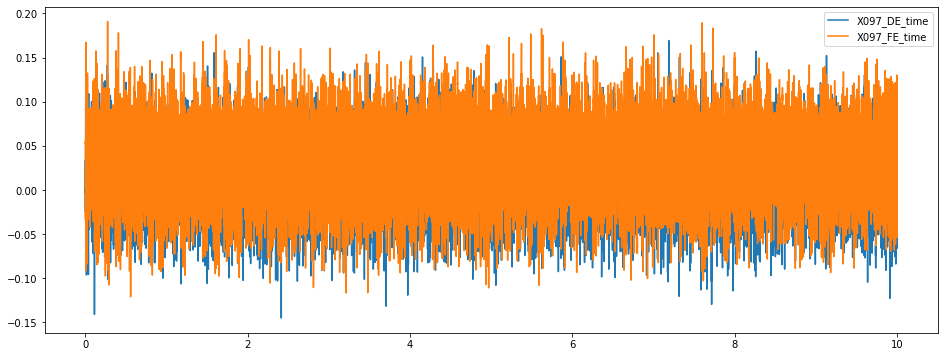

In [67]:
df_normal.rolling(window=10).mean().plot(figsize=(16,6))

array([[<AxesSubplot:title={'center':'X298_DE_time'}>,
        <AxesSubplot:title={'center':'X298_FE_time'}>]], dtype=object)

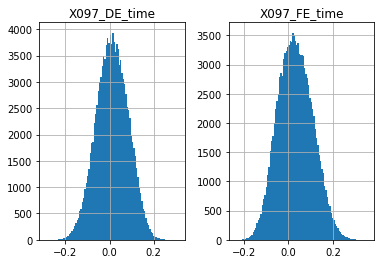

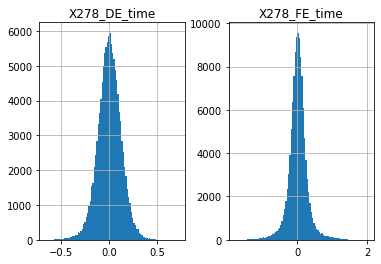

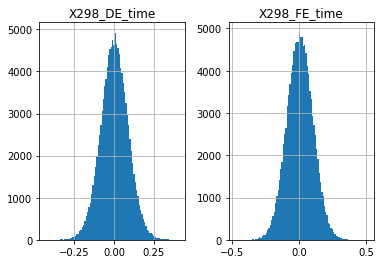

In [90]:
df_normal.hist(bins=100)
df_fault_IR_007.hist(bins=100)
df_fault_OR_007.hist(bins=100)

In total 120000 samples, freq is 12000.0 Hz, total time is 10.0 sec
In total 120000 samples, freq is 12000.0 Hz, total time is 10.0 sec
In total 120000 samples, freq is 12000.0 Hz, total time is 10.0 sec


,amp_n,freq_n,amp_fault_ir,freq_fault_ir,amp_fault_or,freq_fault_or
0,12.946389,0.0,2.849548,0.0,2.079666,0.0
1,15.718531,0.1,7.904962,0.1,3.981529,0.1
2,18.473001,0.2,3.875309,0.2,2.611148,0.2
3,27.289405,0.3,2.426454,0.3,1.767003,0.3
4,12.111476,0.4,1.713216,0.4,3.337818,0.4


(-10.0, 600.0)

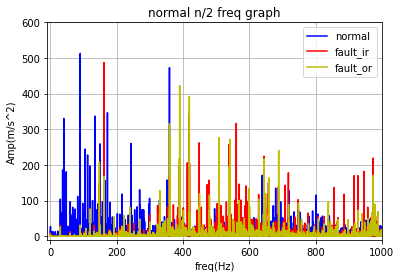

In [94]:
# frequency analysis of normal and faulty signals
from scipy.fft import rfft, rfftfreq
from scipy.fft import fft, fftfreq, fftshift


def calculate_fft_signal(sig, sample_freq):
    num_samples = len(sig)
    t = num_samples / sample_freq
    print("In total %s samples, freq is %s Hz, total time is %s sec" %(num_samples, sample_freq, t))
    s = sig - np.mean(sig) # substract mean value to reduce amp of 0 Hz
    w = np.hanning(len(s)) # hanning window
    y = rfft(s * w)
    amp = np.abs(y) # calculate amplification
    freq = rfftfreq(n=num_samples, d=1/sample_freq)
    return amp, freq

# calculate fft and convert to dataframe
sample_freq = 12000.0 # get from file name and data descrip
amp, freq = calculate_fft_signal(df_normal['X097_DE_time'].values, sample_freq)
df_fft = pd.DataFrame(np.array([amp, freq]).T,  columns=["amp_n", "freq_n"])
df_fft['amp_fault_ir'], df_fft['freq_fault_ir'] = calculate_fft_signal(df_fault_IR_007['X278_DE_time'].values, sample_freq)
df_fft['amp_fault_or'], df_fft['freq_fault_or'] = calculate_fft_signal(df_fault_OR_007['X298_DE_time'].values, sample_freq)

display(df_fft.head())

# plot freq graph for both normal and fault data
fig1 = plt.plot(df_fft['freq_n'].values, df_fft['amp_n'].values, 'b-', label='normal')
plt.plot(df_fft['freq_fault_ir'].values, df_fft['amp_fault_ir'].values, 'r-', label='fault_ir')
plt.plot(df_fft['freq_fault_or'].values, df_fft['amp_fault_or'].values, 'y-', label='fault_or')

plt.xlabel('freq(Hz)')
plt.ylabel('Amp(m/s^2)')
plt.grid()
plt.legend()
plt.title('normal n/2 freq graph')
plt.xlim(-10, 1000)
plt.ylim(-10, 600)

,amp_n,freq_n,amp_fault_ir,freq_fault_ir,amp_fault_or,freq_fault_or
0,12.946389,0.0,2.849548,0.0,2.079666,0.0
299,92.274663,29.9,30.247720,29.9,26.458362,29.9
300,103.942895,30.0,18.185516,30.0,23.554033,30.0
599,25.729154,59.9,13.338449,59.9,8.275519,59.9
600,97.313052,60.0,8.177172,60.0,3.153684,60.0


,amp_n,freq_n,amp_fault_ir,freq_fault_ir,amp_fault_or,freq_fault_or
900,512.812099,90.0,2.555905,90.0,2.095224,90.0
3592,472.844403,359.2,69.789189,359.2,192.451100,359.2
1721,346.433339,172.1,0.252700,172.1,0.595950,172.1
1352,336.990262,135.2,0.370001,135.2,0.292149,135.2
404,330.415617,40.4,0.165298,40.4,0.222647,40.4
3591,318.521994,359.1,62.607680,359.1,70.485817,359.1
1720,308.891906,172.0,0.600852,172.0,0.048649,172.0
1612,299.511837,161.2,0.563878,161.2,2.262563,161.2
899,272.716757,89.9,4.261180,89.9,21.783894,89.9
2433,260.483944,243.3,1.704928,243.3,1.036362,243.3


,amp_n,freq_n,amp_fault_ir,freq_fault_ir,amp_fault_or,freq_fault_or
1617,17.958382,161.7,487.156635,161.7,167.064022,161.7
1616,31.639727,161.6,435.108226,161.6,41.651595,161.6
4188,8.215961,418.8,340.022366,418.8,7.810994,418.8
5608,2.890855,560.8,316.752030,560.8,2.142392,560.8
4487,1.764573,448.7,262.093366,448.7,8.006500,448.7
5385,12.190754,538.5,257.372419,538.5,20.999267,538.5
6445,5.216930,644.5,224.462349,644.5,3.171816,644.5
4189,8.926458,418.9,223.307462,418.9,28.106350,418.9
9731,16.253242,973.1,219.187174,973.1,3.619626,973.1
4488,5.306998,448.8,211.407734,448.8,12.496230,448.8


,amp_n,freq_n,amp_fault_ir,freq_fault_ir,amp_fault_or,freq_fault_or
3900,6.123077,390.0,8.442479,390.0,422.952019,390.0
4192,24.999152,419.2,37.943384,419.2,392.410556,419.2
3593,172.309814,359.3,21.796495,359.3,315.681667,359.3
3601,3.495512,360.1,16.950194,360.1,280.370809,360.1
4191,23.709063,419.1,87.023984,419.1,252.404259,419.1
3901,8.025336,390.1,10.719955,390.1,244.789999,390.1
3892,43.188624,389.2,45.183160,389.2,217.910333,389.2
3600,4.104665,360.0,54.197988,360.0,212.115191,360.0
1477,16.899606,147.7,141.182636,147.7,208.081987,147.7
1478,19.283649,147.8,26.995604,147.8,204.381062,147.8


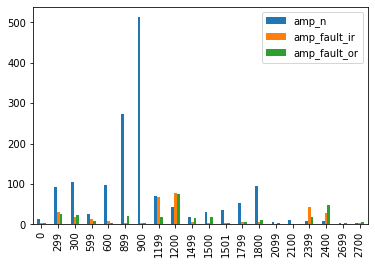

In [99]:
# check the amplification of 1st/2nd/3rd order of rotating freq
rpm = 1796
rotate_freq = rpm / 60 # rpm = Rotates Per Minute; Hz = RPM ÷ 60
rotate_freq = 30

# get the amplication of n-order of rotating frequency
num_oders = 10
df_freq_rpm = pd.DataFrame()
for i in range(num_oders):
    df_freq_rpm = pd.concat( [df_freq_rpm, df_fft[abs(df_fft['freq_n'] - rotate_freq*i) < 0.1] ] )
#df_freq_rpm.index = df_freq_rpm['freq_n']
display(df_freq_rpm.head())
df_freq_rpm.plot.bar(y=['amp_n','amp_fault_ir','amp_fault_or'])

# get freq of max 5 amp, only check data below 1Khz
sorted_df_fft = df_fft[df_fft['freq_n'] < 1000].sort_values(by='amp_n', ascending=False)
display(sorted_df_fft[:10])

sorted_df_fft = df_fft[df_fft['freq_n'] < 1000].sort_values(by='amp_fault_ir', ascending=False)
display(sorted_df_fft[:10])

sorted_df_fft = df_fft[df_fft['freq_n'] < 500].sort_values(by='amp_fault_or', ascending=False)
display(sorted_df_fft[:30])

In [ ]:
# use PSD to calculate and compare
# welch